# Metamer-SAE — Notebook 04B
## PCA visualization extension: paired structure, component loadings and image-linked diagnostics

This notebook **does not refit PCA**. It loads the saved outputs from the completed Notebook 04 run and creates richer diagnostic figures from the eight Feather development triplets.

### What this adds

1. A clearer scree plot showing individual and cumulative component variance.
2. Paired PCA projections with source-to-standard and source-to-adversarial trajectories across several component planes.
3. Standardized PCA-score heatmaps for all three conditions.
4. Signed, component-wise source-to-metamer displacement heatmaps.
5. Cumulative paired distances as more PCA components are included.
6. A direct standard-versus-adversarial distance comparison for each development image.
7. PCA loading visualizations showing which of the 384 pooled ConvNeXt channels contribute most to each component.
8. A source/standard/adversarial image gallery linked to the PCA distances.

### Data discipline

- Uses the **existing fitted PCA model** from Notebook 04.
- Uses only the eight already-designated Feather **development** triplets for stimulus visualizations.
- Does not load the 32 primary-evaluation triplets or eight reserve triplets.
- Does not refit normalization, PCA, or any other representation.
- PCA is fitted to pooled observer activations; its components are directions across 384 channels, **not image pixels and not spatial heatmaps**.

The colours are consistent across figures: source = blue, standard metamer = orange, adversarial metamer = green.

## 1. Load the existing PCA run and its saved development outputs

Run this after Notebook 04 has completed and saved its PCA run folder to Google Drive. The cell selects the most recent run folder by its timestamped name; change `RUN_ID_OVERRIDE` only when you intentionally want to inspect a particular run.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display

PROJECT_ROOT = Path('/content/drive/MyDrive/metamer-sae')
PCA_RUNS_ROOT = PROJECT_ROOT / 'representations' / 'pca' / 'runs'
RUN_ID_OVERRIDE = None  # e.g. 'pca_20261119T065920Z'; leave None for latest

if RUN_ID_OVERRIDE is None:
    run_dirs = sorted(
        [p for p in PCA_RUNS_ROOT.iterdir() if p.is_dir() and p.name.startswith('pca_')],
        key=lambda p: p.name,
    )
    if not run_dirs:
        raise FileNotFoundError(f'No saved PCA runs found in {PCA_RUNS_ROOT}')
    RUN_DIR = run_dirs[-1]
else:
    RUN_DIR = PCA_RUNS_ROOT / RUN_ID_OVERRIDE

FIGURE_DIR = RUN_DIR / 'figures'
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

with (RUN_DIR / 'pca_run_config.json').open('r', encoding='utf-8') as f:
    pca_config = json.load(f)

pca = joblib.load(RUN_DIR / 'pca_full_384_components.joblib')
embeddings = pd.read_csv(RUN_DIR / 'pca_development_embeddings.csv')
pair_distances = pd.read_csv(RUN_DIR / 'pca_development_pair_distances.csv')
component_metrics = pd.read_csv(RUN_DIR / 'pca_component_retention_metrics.csv')

SELECTED_K = int(pca_config['selected_components'])
PC_COLS = [f'pc{i}' for i in range(1, SELECTED_K + 1)]
CONDITIONS = ['source', 'standard', 'adversarial']
COLORS = {
    'source': '#4C78A8',
    'standard': '#F28E2B',
    'adversarial': '#54A24B',
}
MARKERS = {'source': 'o', 'standard': 's', 'adversarial': '^'}

required_cols = {'sample_id', 'condition', *PC_COLS}
missing = required_cols - set(embeddings.columns)
if missing:
    raise ValueError(f'Missing columns in development embeddings: {sorted(missing)}')
if set(embeddings['condition'].unique()) != set(CONDITIONS):
    raise ValueError(f'Unexpected conditions: {embeddings.condition.unique().tolist()}')

sample_ids = sorted(embeddings['sample_id'].unique().tolist())
if len(sample_ids) != 8:
    raise ValueError(f'Expected the eight development triplets, found {len(sample_ids)}')
if len(embeddings) != 24:
    raise ValueError(f'Expected 24 rows (8 triplets × 3 conditions), found {len(embeddings)}')

scores = {}
for condition in CONDITIONS:
    rows = []
    for sample_id in sample_ids:
        match = embeddings.loc[
            embeddings['sample_id'].eq(sample_id) & embeddings['condition'].eq(condition), PC_COLS
        ]
        if len(match) != 1:
            raise ValueError(f'Expected exactly one {condition} row for {sample_id}; found {len(match)}')
        rows.append(match.iloc[0].to_numpy(dtype=np.float64))
    scores[condition] = np.vstack(rows)

pc_sd = np.sqrt(np.maximum(pca.explained_variance_[:SELECTED_K], 1e-12))
explained = pca.explained_variance_ratio_

print('Loaded PCA run:', RUN_DIR.name)
print('Selected components:', SELECTED_K)
print('Development IDs:', sample_ids)
print('Embedding matrices:', {k: v.shape for k, v in scores.items()})
print('Primary evaluation loaded:', pca_config.get('primary_evaluation_loaded'))
print('Reserve loaded:', pca_config.get('reserve_loaded'))
assert pca_config.get('primary_evaluation_loaded') is False
assert pca_config.get('reserve_loaded') is False

Mounted at /content/drive
Loaded PCA run: pca_20261119T065920Z
Selected components: 16
Development IDs: ['feather_0000', 'feather_0027', 'feather_0084', 'feather_0097', 'feather_0119', 'feather_0199', 'feather_0260', 'feather_0308']
Embedding matrices: {'source': (8, 16), 'standard': (8, 16), 'adversarial': (8, 16)}
Primary evaluation loaded: False
Reserve loaded: False


In [ ]:
# ================================================================
# ADDITIONAL PCA VISUALIZATIONS — DATA PREPARATION
# Load aligned pooled development activations
# ================================================================

FEATHER_ACTIVATION_DIRS = {
    'source': PROJECT_ROOT / 'activations' / 'feather' / 'source',
    'standard': PROJECT_ROOT / 'activations' / 'feather' / 'standard_resnet50',
    'adversarial': PROJECT_ROOT / 'activations' / 'feather' / 'adversarial_resnet50',
}

raw_dev_by_condition = {}

def get_pca_sample_id(filename):
    return '_'.join(Path(str(filename)).stem.split('_')[:2])

for condition, directory in FEATHER_ACTIVATION_DIRS.items():

    metadata = pd.read_csv(directory / 'metadata.csv')
    activation_array = np.load(
        directory / 'pooled_activations.npy',
        mmap_mode='r',
        allow_pickle=False
    )

    metadata['sample_id'] = metadata['filename'].map(get_pca_sample_id)

    dev_meta = metadata.loc[
        metadata['split'].astype(str).eq('development')
    ].copy()

    dev_meta = dev_meta.set_index('sample_id').loc[sample_ids]

    indices = dev_meta['activation_index'].astype(int).to_numpy()

    X_dev = np.asarray(
        activation_array[indices],
        dtype=np.float32
    )

    assert X_dev.shape == (8, 384)
    assert np.isfinite(X_dev).all()

    raw_dev_by_condition[condition] = X_dev

print("Development activations successfully loaded.")

for condition, X in raw_dev_by_condition.items():
    print(f"{condition}: {X.shape}")

Development activations successfully loaded.
source: (8, 384)
standard: (8, 384)
adversarial: (8, 384)


/tmp/ipykernel_624/2957651534.py:120: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


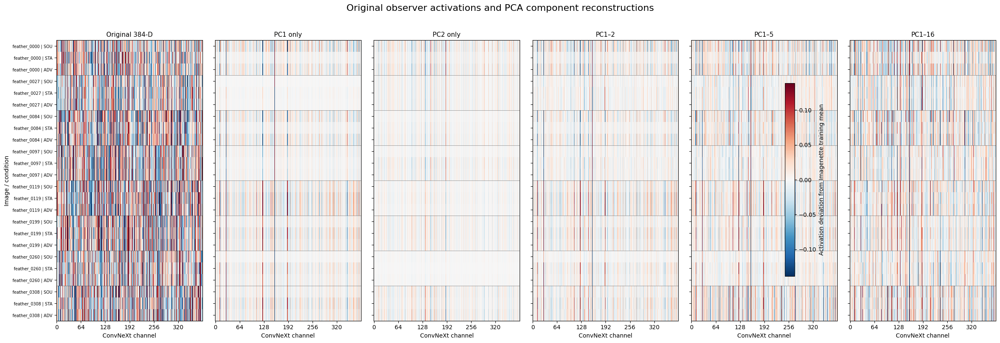

In [ ]:
# ================================================================
# FIGURE: ORIGINAL ACTIVATIONS VS PCA RECONSTRUCTIONS
# ================================================================

stimulus_order = [
    (sample_id, condition)
    for sample_id in sample_ids
    for condition in CONDITIONS
]

X_dev_ordered = np.vstack([
    raw_dev_by_condition[condition][sample_ids.index(sample_id)]
    for sample_id, condition in stimulus_order
])

row_labels = [
    f"{sid} | {cond[:3].upper()}"
    for sid, cond in stimulus_order
]

# Project using the existing fitted PCA.
Z_dev_full = pca.transform(X_dev_ordered)

# Reconstruct using selected component subsets.
component_specs = [
    ('Original 384-D', None),
    ('PC1 only', [0]),
    ('PC2 only', [1]),
    ('PC1–2', [0, 1]),
    ('PC1–5', list(range(5))),
    (f'PC1–{SELECTED_K}', list(range(SELECTED_K))),
]

reconstructions = {}

reconstructions['Original 384-D'] = X_dev_ordered.copy()

for label, component_indices in component_specs[1:]:

    Z_partial = np.zeros_like(Z_dev_full)

    Z_partial[:, component_indices] = (
        Z_dev_full[:, component_indices]
    )

    X_reconstructed = pca.inverse_transform(Z_partial)

    reconstructions[label] = X_reconstructed

# Centre every activation pattern using the Imagenette training mean.
# This emphasizes changes relative to the natural-image reference distribution.
centered_patterns = {
    label: values - pca.mean_[None, :]
    for label, values in reconstructions.items()
}

common_limit = np.quantile(
    np.abs(np.concatenate([
        value.ravel()
        for value in centered_patterns.values()
    ])),
    0.98
)

fig, axes = plt.subplots(
    1, len(centered_patterns),
    figsize=(24, 8),
    sharey=True
)

for ax, (label, matrix) in zip(
    axes, centered_patterns.items()
):

    im = ax.imshow(
        matrix,
        aspect='auto',
        cmap='RdBu_r',
        vmin=-common_limit,
        vmax=common_limit,
        interpolation='nearest'
    )

    ax.set_title(label, fontsize=11)
    ax.set_xlabel('ConvNeXt channel')

    ax.set_xticks(
        np.arange(0, 384, 64)
    )

    ax.set_xticklabels(
        np.arange(0, 384, 64)
    )

    for separator in range(3, 24, 3):
        ax.axhline(
            separator - 0.5,
            color='black',
            linewidth=0.5,
            alpha=0.5
        )

axes[0].set_yticks(np.arange(24))
axes[0].set_yticklabels(row_labels, fontsize=7)
axes[0].set_ylabel('Image / condition')

fig.colorbar(
    im,
    ax=axes,
    shrink=0.75,
    label='Activation deviation from Imagenette training mean'
)

fig.suptitle(
    'Original observer activations and PCA component reconstructions',
    fontsize=16,
    y=1.02
)

fig.tight_layout()

fig.savefig(
    FIGURE_DIR / 'pca_viz_10_activation_reconstruction_heatmaps.png',
    dpi=220,
    bbox_inches='tight'
)

plt.show()

/tmp/ipykernel_624/4091222639.py:115: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


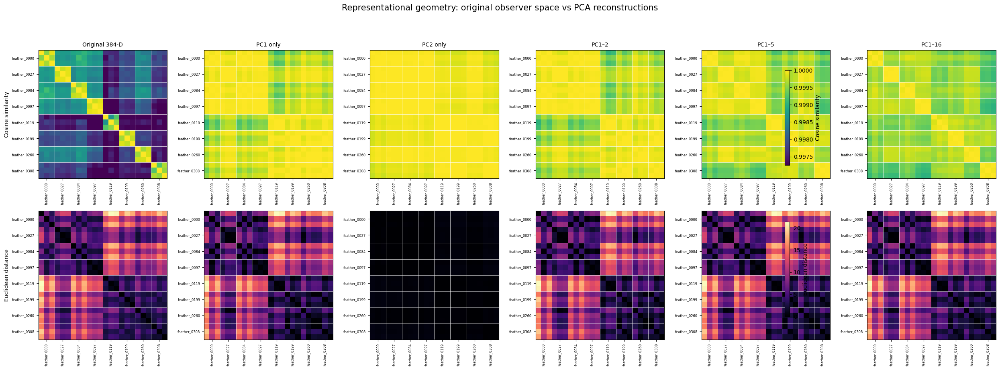

Similarity matrices generated for:
['Original 384-D', 'PC1 only', 'PC2 only', 'PC1–2', 'PC1–5', 'PC1–16']


In [ ]:
# ================================================================
# FIGURE: REPRESENTATIONAL SIMILARITY MATRIX RECONSTRUCTIONS
# ================================================================

from sklearn.metrics.pairwise import (
    cosine_similarity,
    euclidean_distances
)

similarity_matrices = {}
distance_matrices = {}

for label, X_reconstructed in reconstructions.items():

    similarity_matrices[label] = cosine_similarity(
        X_reconstructed
    )

    distance_matrices[label] = euclidean_distances(
        X_reconstructed
    )

labels = list(reconstructions.keys())

all_similarities = np.concatenate([
    similarity_matrices[label].ravel()
    for label in labels
])

sim_min = np.quantile(all_similarities, 0.02)
sim_max = np.quantile(all_similarities, 0.98)

dist_max = max(
    matrix.max()
    for matrix in distance_matrices.values()
)

fig, axes = plt.subplots(
    2, len(labels),
    figsize=(25, 9)
)

tick_positions = np.arange(1, 24, 3)

for col, label in enumerate(labels):

    # First row: cosine similarity.
    ax1 = axes[0, col]

    im1 = ax1.imshow(
        similarity_matrices[label],
        cmap='viridis',
        vmin=sim_min,
        vmax=sim_max,
        interpolation='nearest'
    )

    ax1.set_title(label, fontsize=10)

    # Second row: pairwise Euclidean distance.
    ax2 = axes[1, col]

    im2 = ax2.imshow(
        distance_matrices[label],
        cmap='magma',
        vmin=0,
        vmax=dist_max,
        interpolation='nearest'
    )

    # Show triplet identities at the centre of each 3-image group.
    for ax in (ax1, ax2):

        ax.set_xticks(tick_positions)
        ax.set_xticklabels(sample_ids, rotation=90, fontsize=6)

        ax.set_yticks(tick_positions)
        ax.set_yticklabels(sample_ids, fontsize=6)

        for boundary in range(3, 24, 3):
            ax.axhline(
                boundary - 0.5,
                color='white',
                linewidth=0.5
            )
            ax.axvline(
                boundary - 0.5,
                color='white',
                linewidth=0.5
            )

axes[0, 0].set_ylabel('Cosine similarity')
axes[1, 0].set_ylabel('Euclidean distance')

fig.colorbar(
    im1,
    ax=axes[0, :].tolist(),
    shrink=0.75,
    label='Cosine similarity'
)

fig.colorbar(
    im2,
    ax=axes[1, :].tolist(),
    shrink=0.75,
    label='Euclidean distance'
)

fig.suptitle(
    'Representational geometry: original observer space vs PCA reconstructions',
    fontsize=15,
    y=1.02
)

fig.tight_layout()

fig.savefig(
    FIGURE_DIR / 'pca_viz_11_representational_similarity_matrices.png',
    dpi=220,
    bbox_inches='tight'
)

plt.show()

print("Similarity matrices generated for:")
print(labels)

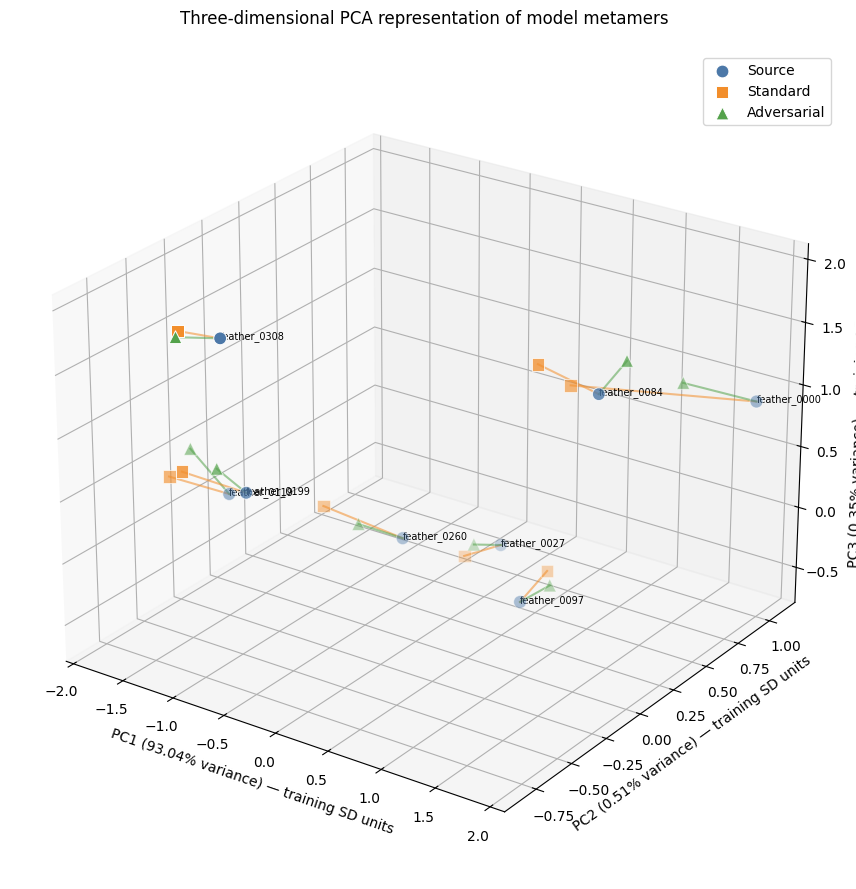

In [ ]:
# ================================================================
# FIGURE: 3D PCA REPRESENTATION SPACE
# ================================================================

from mpl_toolkits.mplot3d import Axes3D

if SELECTED_K < 3:
    raise ValueError("At least three selected components are required.")

# Standardize axes using training PCA standard deviations.
# This is for visualization only; the fitted PCA is unchanged.
component_sd_3d = np.sqrt(
    pca.explained_variance_[:3]
)

coordinates_3d = {
    condition: scores[condition][:, :3] / component_sd_3d[None, :]
    for condition in CONDITIONS
}

fig = plt.figure(figsize=(12, 9))
ax = fig.add_subplot(111, projection='3d')

# Connecting lines for the matched triplets.
for i, sid in enumerate(sample_ids):

    source = coordinates_3d['source'][i]
    standard = coordinates_3d['standard'][i]
    adversarial = coordinates_3d['adversarial'][i]

    ax.plot(
        [source[0], standard[0]],
        [source[1], standard[1]],
        [source[2], standard[2]],
        color=COLORS['standard'],
        alpha=0.55,
        linewidth=1.5
    )

    ax.plot(
        [source[0], adversarial[0]],
        [source[1], adversarial[1]],
        [source[2], adversarial[2]],
        color=COLORS['adversarial'],
        alpha=0.55,
        linewidth=1.5
    )

# Plot the three conditions.
for condition in CONDITIONS:

    points = coordinates_3d[condition]

    ax.scatter(
        points[:, 0],
        points[:, 1],
        points[:, 2],
        color=COLORS[condition],
        marker=MARKERS[condition],
        s=85,
        edgecolor='white',
        linewidth=0.7,
        label=condition.title()
    )

# Label source anchors only.
for i, sid in enumerate(sample_ids):

    source = coordinates_3d['source'][i]

    ax.text(
        source[0],
        source[1],
        source[2],
        sid,
        fontsize=7
    )

variance = 100 * pca.explained_variance_ratio_[:3]

ax.set_xlabel(f'PC1 ({variance[0]:.2f}% variance) — training SD units')
ax.set_ylabel(f'PC2 ({variance[1]:.2f}% variance) — training SD units')
ax.set_zlabel(f'PC3 ({variance[2]:.2f}% variance) — training SD units')

ax.set_title(
    'Three-dimensional PCA representation of model metamers',
    pad=20
)

ax.view_init(elev=25, azim=-55)

ax.legend()
plt.tight_layout()

fig.savefig(
    FIGURE_DIR / 'pca_viz_12_three_dimensional_pca.png',
    dpi=220,
    bbox_inches='tight'
)

plt.show()

### 2A. Check whether PC1 is dominated by activation scale or unusually variable channels

The original run reports that PC1 explains 93.04% of total variance, and that the across-channel standard deviations are highly unequal. This is not automatically an error, but it is important to understand before interpreting PC1 as a meaningful visual difference. This audit ranks channels by training-set standard deviation and checks whether PC1 scores track simple activation-magnitude summaries on Imagenette training images.

Highest-variance observer channels:


,feature_index,std,mean,min,p99,max
0,156,5.767517,36.146366,23.839400,53.069695,62.084330
1,29,0.266984,-0.174097,-1.224222,0.347219,0.663611
2,124,0.256403,-0.145829,-0.912311,0.395535,0.581182
3,189,0.203836,-0.186425,-1.419250,0.170773,0.310639
4,83,0.177022,-0.056168,-0.588213,0.458148,0.812220
5,150,0.164486,0.080929,-0.570774,0.351815,0.463403
6,146,0.163287,-0.046657,-0.545109,0.308752,0.482179
7,132,0.158440,-0.077457,-0.931864,0.270985,0.520981
8,135,0.156697,0.147845,-0.364299,0.579869,0.932958
9,238,0.149606,0.003701,-0.538216,0.303907,0.526295


Top PC1 loading channels:


,observer_channel,pc1_loading,pc1_absolute_loading,std
156,156,0.997425,0.997425,5.767517
29,29,-0.036543,0.036543,0.266984
124,124,-0.020698,0.020698,0.256403
12,12,-0.015116,0.015116,0.120908
190,190,-0.013615,0.013615,0.145008
189,189,-0.012146,0.012146,0.203836
348,348,0.011774,0.011774,0.103695
125,125,-0.011599,0.011599,0.103426
146,146,-0.008873,0.008873,0.163287
109,109,-0.008857,0.008857,0.112108


PC1 association with simple activation-magnitude summaries (Imagenette train):


,summary,pearson_r,spearman_rho
0,L2 norm,1.0000,1.0000
1,Mean absolute activation,0.8997,0.8918
2,Maximum absolute activation,1.0000,1.0000


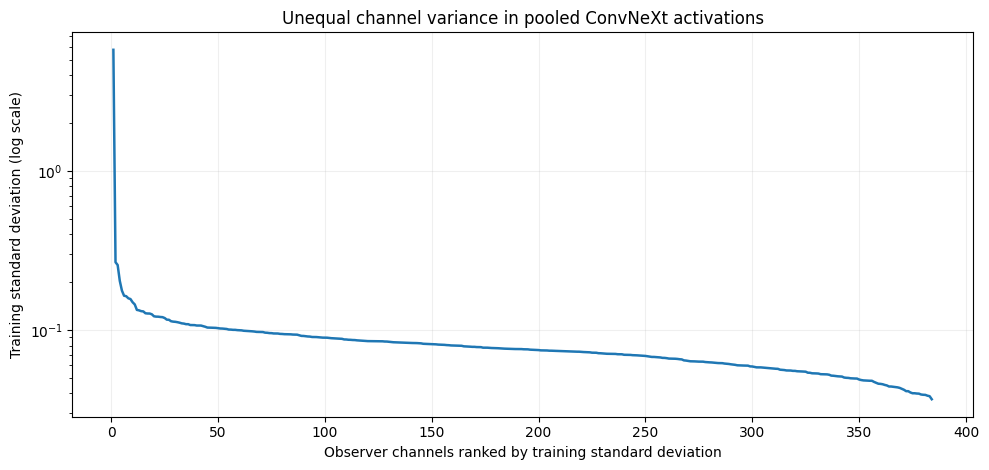

In [ ]:
feature_stats_path = RUN_DIR / 'pca_training_feature_statistics.csv'
if not feature_stats_path.is_file():
    raise FileNotFoundError(f'Training feature statistics not found: {feature_stats_path}')
feature_stats = pd.read_csv(feature_stats_path)

# Reload only Imagenette training activations; no Feather evaluation data are used here.
train_array_path = PROJECT_ROOT / 'activations' / 'natural_images' / 'train' / 'pooled_activations.npy'
X_train_check = np.load(train_array_path, mmap_mode='r', allow_pickle=False)
if X_train_check.shape != (9469, 384):
    raise ValueError(f'Unexpected training activation shape: {X_train_check.shape}')

X_train_check = np.asarray(X_train_check, dtype=np.float32)
train_pc1 = pca.transform(X_train_check)[:, 0]
train_l2 = np.linalg.norm(X_train_check, axis=1)
train_mean_abs = np.mean(np.abs(X_train_check), axis=1)
train_max_abs = np.max(np.abs(X_train_check), axis=1)

magnitude_correlations = pd.DataFrame([
    {'summary': 'L2 norm', 'pearson_r': np.corrcoef(train_pc1, train_l2)[0, 1],
     'spearman_rho': pd.Series(train_pc1).corr(pd.Series(train_l2), method='spearman')},
    {'summary': 'Mean absolute activation', 'pearson_r': np.corrcoef(train_pc1, train_mean_abs)[0, 1],
     'spearman_rho': pd.Series(train_pc1).corr(pd.Series(train_mean_abs), method='spearman')},
    {'summary': 'Maximum absolute activation', 'pearson_r': np.corrcoef(train_pc1, train_max_abs)[0, 1],
     'spearman_rho': pd.Series(train_pc1).corr(pd.Series(train_max_abs), method='spearman')},
])

std_ranked = feature_stats.sort_values('std', ascending=False).reset_index(drop=True)
std_ranked['std_rank'] = np.arange(1, len(std_ranked) + 1)
pc1_loading_rank = pd.DataFrame({
    'observer_channel': np.arange(pca.components_.shape[1]),
    'pc1_loading': pca.components_[0],
    'pc1_absolute_loading': np.abs(pca.components_[0]),
})
pc1_loading_rank = pc1_loading_rank.merge(
    feature_stats[['feature_index', 'std']].rename(columns={'feature_index': 'observer_channel'}),
    on='observer_channel', how='left'
).sort_values('pc1_absolute_loading', ascending=False)

print('Highest-variance observer channels:')
display(std_ranked[['feature_index', 'std', 'mean', 'min', 'p99', 'max']].head(15))
print('Top PC1 loading channels:')
display(pc1_loading_rank.head(15))
print('PC1 association with simple activation-magnitude summaries (Imagenette train):')
display(magnitude_correlations.round(4))

fig, ax = plt.subplots(figsize=(10, 4.8))
ax.plot(std_ranked['std_rank'], std_ranked['std'], linewidth=1.8)
ax.set_yscale('log')
ax.set_xlabel('Observer channels ranked by training standard deviation')
ax.set_ylabel('Training standard deviation (log scale)')
ax.set_title('Unequal channel variance in pooled ConvNeXt activations')
ax.grid(alpha=0.2)
fig.tight_layout()
fig.savefig(FIGURE_DIR / 'pca_viz_00_channel_variance_audit.png', dpi=200, bbox_inches='tight')
plt.show()

magnitude_correlations.to_csv(RUN_DIR / 'pca_pc1_magnitude_correlations.csv', index=False)
pc1_loading_rank.to_csv(RUN_DIR / 'pca_pc1_loading_and_channel_scale.csv', index=False)

## 2. Scree plot: how much variance does each component explain?

Notebook 04 showed cumulative variance. This version makes the contribution of each of the first selected components visible, which is important because the first component accounts for a very large fraction of the total variance.

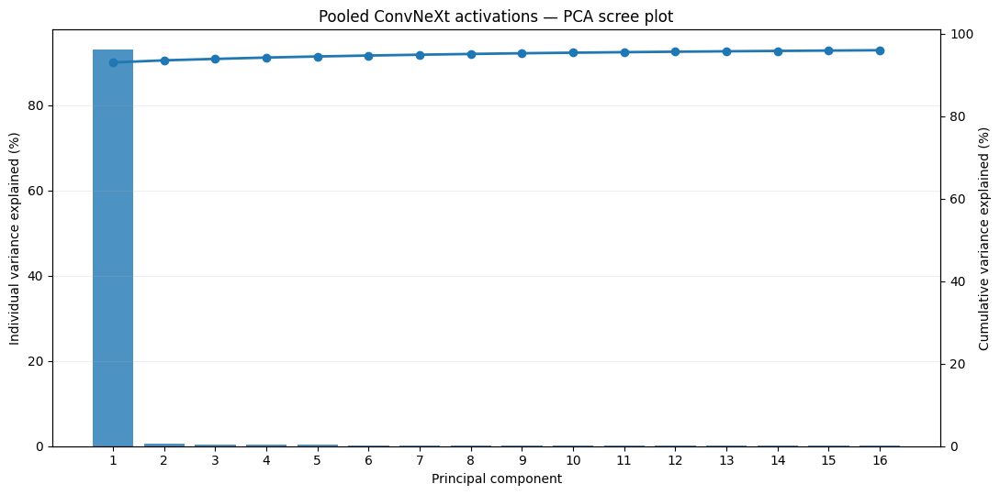

PC1 explains 93.04% of training variance.
First 16 components explain 96.01% of training variance.


In [ ]:
fig, ax1 = plt.subplots(figsize=(11, 5.5))
pcs = np.arange(1, SELECTED_K + 1)
ax1.bar(pcs, 100 * explained[:SELECTED_K], alpha=0.8, label='Individual variance explained (%)')
ax1.set_xlabel('Principal component')
ax1.set_ylabel('Individual variance explained (%)')
ax1.set_xticks(pcs)
ax1.set_title('Pooled ConvNeXt activations — PCA scree plot')
ax2 = ax1.twinx()
ax2.plot(pcs, 100 * np.cumsum(explained[:SELECTED_K]), marker='o', linewidth=2, label='Cumulative variance (%)')
ax2.set_ylabel('Cumulative variance explained (%)')
ax2.set_ylim(0, 101)
ax1.grid(axis='y', alpha=0.2)
fig.tight_layout()
fig.savefig(FIGURE_DIR / 'pca_viz_01_scree_first_selected_components.png', dpi=200, bbox_inches='tight')
plt.show()

print(f'PC1 explains {100 * explained[0]:.2f}% of training variance.')
print(f'First {SELECTED_K} components explain {100 * explained[:SELECTED_K].sum():.2f}% of training variance.')

## 3. Paired PCA projections with trajectories

Each natural source is connected to its own standard and adversarial metamer. The three panels show different component planes, not three independently fitted PCAs. The basis is the same fitted training PCA throughout.

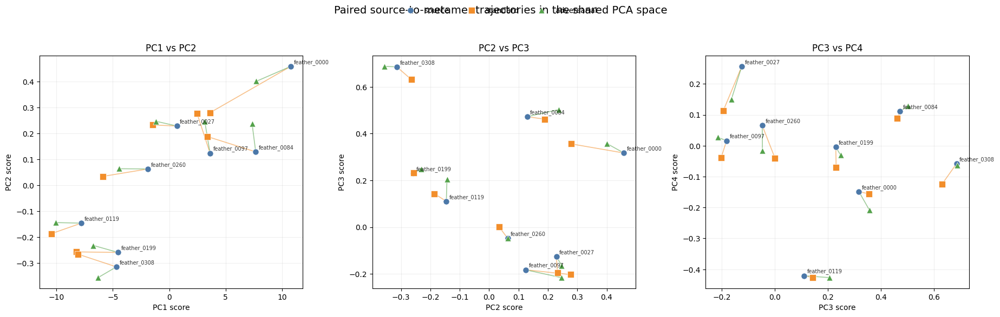

In [ ]:
pair_planes = [(1, 2), (2, 3), (3, 4)]
pair_planes = [(a, b) for a, b in pair_planes if b <= SELECTED_K]
fig, axes = plt.subplots(1, len(pair_planes), figsize=(6.2 * len(pair_planes), 5.6), squeeze=False)

for ax, (pc_x, pc_y) in zip(axes[0], pair_planes):
    ix, iy = pc_x - 1, pc_y - 1
    for i, sample_id in enumerate(sample_ids):
        src = scores['source'][i]
        std = scores['standard'][i]
        adv = scores['adversarial'][i]
        ax.plot([src[ix], std[ix]], [src[iy], std[iy]], color=COLORS['standard'], alpha=0.55, linewidth=1.2)
        ax.plot([src[ix], adv[ix]], [src[iy], adv[iy]], color=COLORS['adversarial'], alpha=0.55, linewidth=1.2)

    for condition in CONDITIONS:
        ax.scatter(
            scores[condition][:, ix], scores[condition][:, iy],
            c=COLORS[condition], marker=MARKERS[condition], s=65,
            edgecolor='white', linewidth=0.5, label=condition, zorder=3,
        )

    # Label source anchors only to reduce clutter.
    for i, sample_id in enumerate(sample_ids):
        ax.annotate(sample_id, (scores['source'][i, ix], scores['source'][i, iy]),
                    xytext=(4, 4), textcoords='offset points', fontsize=7, alpha=0.8)
    ax.set_xlabel(f'PC{pc_x} score')
    ax.set_ylabel(f'PC{pc_y} score')
    ax.set_title(f'PC{pc_x} vs PC{pc_y}')
    ax.grid(alpha=0.2)

handles, labels = axes[0][0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper center', ncol=3, frameon=False)
fig.suptitle('Paired source-to-metamer trajectories in the shared PCA space', y=1.04, fontsize=14)
fig.tight_layout()
fig.savefig(FIGURE_DIR / 'pca_viz_02_paired_projection_planes.png', dpi=200, bbox_inches='tight')
plt.show()

## 4. Condition score heatmaps

Each cell is a PCA score divided by the training-set standard deviation of that component. This gives a comparable scale across components; it does not change the fitted PCA or imply that the PC dimensions are independent in the stimulus sample.

/tmp/ipykernel_624/1147088631.py:17: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


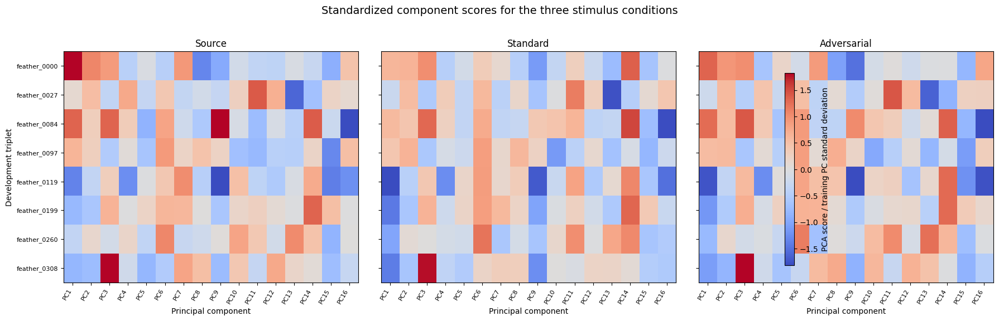

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5.6), sharey=True)
z_scores = {condition: scores[condition] / pc_sd[None, :] for condition in CONDITIONS}
all_z = np.concatenate([z_scores[c].ravel() for c in CONDITIONS])
score_limit = max(float(np.quantile(np.abs(all_z), 0.98)), 1.0)

for ax, condition in zip(axes, CONDITIONS):
    im = ax.imshow(z_scores[condition], aspect='auto', cmap='coolwarm', vmin=-score_limit, vmax=score_limit)
    ax.set_title(f'{condition.title()}')
    ax.set_xlabel('Principal component')
    ax.set_xticks(np.arange(SELECTED_K))
    ax.set_xticklabels([f'PC{i}' for i in range(1, SELECTED_K + 1)], rotation=60, ha='right', fontsize=8)
    ax.set_yticks(np.arange(len(sample_ids)))
    ax.set_yticklabels(sample_ids, fontsize=8)
axes[0].set_ylabel('Development triplet')
fig.colorbar(im, ax=axes, shrink=0.8, label='PCA score / training PC standard deviation')
fig.suptitle('Standardized component scores for the three stimulus conditions', y=1.02, fontsize=14)
fig.tight_layout()
fig.savefig(FIGURE_DIR / 'pca_viz_03_condition_score_heatmaps.png', dpi=200, bbox_inches='tight')
plt.show()

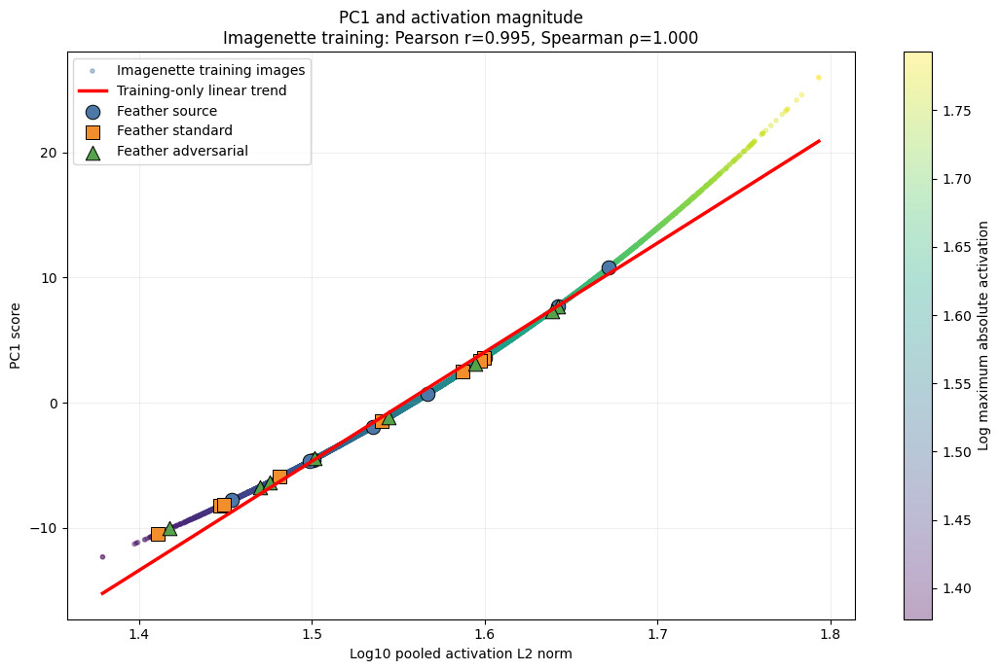

Training-only Pearson correlation: 0.9950115481934989
Training-only Spearman correlation: 0.9999934500878663


In [ ]:
# ================================================================
# FIGURE: PC1 VS ACTIVATION MAGNITUDE
# ================================================================

x_train_plot = np.log10(
    np.maximum(train_l2, 1e-10)
)

y_train_plot = train_pc1

colour_train = np.log10(
    np.maximum(train_max_abs, 1e-10)
)

pearson_r = np.corrcoef(
    x_train_plot,
    y_train_plot
)[0, 1]

spearman_rho = pd.Series(
    x_train_plot
).corr(
    pd.Series(y_train_plot),
    method='spearman'
)

# Training-only descriptive regression.
slope, intercept = np.polyfit(
    x_train_plot,
    y_train_plot,
    1
)

fig, ax = plt.subplots(figsize=(11, 7))

scatter = ax.scatter(
    x_train_plot,
    y_train_plot,
    c=colour_train,
    cmap='viridis',
    s=9,
    alpha=0.35,
    label='Imagenette training images'
)

x_line = np.linspace(
    x_train_plot.min(),
    x_train_plot.max(),
    200
)

ax.plot(
    x_line,
    slope * x_line + intercept,
    color='red',
    linewidth=2.5,
    label='Training-only linear trend'
)

# Overlay the development stimulus conditions.
for condition in CONDITIONS:

    X_condition = raw_dev_by_condition[condition]

    dev_l2 = np.linalg.norm(
        X_condition,
        axis=1
    )

    dev_pc1 = pca.transform(
        X_condition
    )[:, 0]

    ax.scatter(
        np.log10(np.maximum(dev_l2, 1e-10)),
        dev_pc1,
        color=COLORS[condition],
        marker=MARKERS[condition],
        s=110,
        edgecolor='black',
        linewidth=0.7,
        label=f'Feather {condition}'
    )

colourbar = fig.colorbar(
    scatter,
    ax=ax
)

colourbar.set_label(
    'Log maximum absolute activation'
)

ax.set_xlabel('Log10 pooled activation L2 norm')
ax.set_ylabel('PC1 score')

ax.set_title(
    f'PC1 and activation magnitude\n'
    f'Imagenette training: Pearson r={pearson_r:.3f}, '
    f'Spearman ρ={spearman_rho:.3f}'
)

ax.legend()
ax.grid(alpha=0.2)

plt.tight_layout()

fig.savefig(
    FIGURE_DIR / 'pca_viz_14_pc1_activation_magnitude_scatter.png',
    dpi=220,
    bbox_inches='tight'
)

plt.show()

print("Training-only Pearson correlation:", pearson_r)
print("Training-only Spearman correlation:", spearman_rho)

## 5. Paired source-to-metamer component displacement heatmaps

These plots show the **signed** difference in each PC score relative to the matched natural source, expressed in training-PC standard-deviation units. Positive and negative changes are both meaningful. The same eight sample identities are aligned across rows.

/tmp/ipykernel_624/189314450.py:20: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


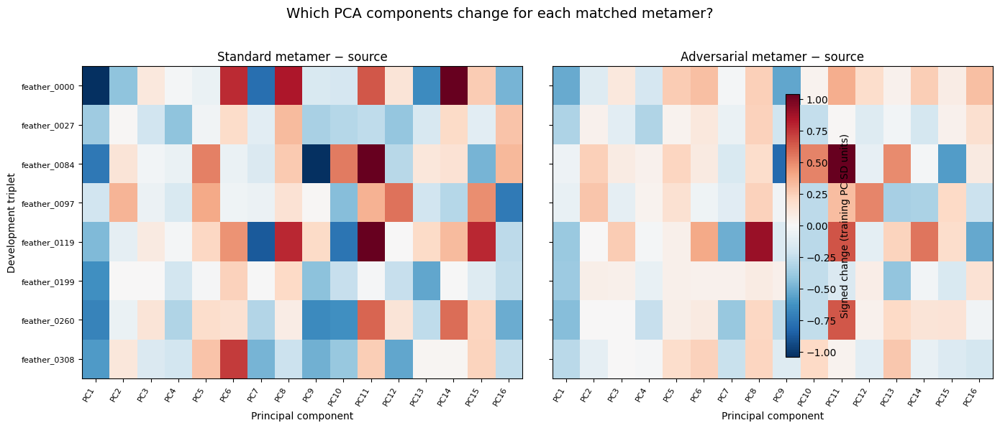

In [ ]:
delta_z = {
    condition: (scores[condition] - scores['source']) / pc_sd[None, :]
    for condition in ('standard', 'adversarial')
}
all_delta = np.concatenate([delta_z[c].ravel() for c in delta_z])
delta_limit = max(float(np.quantile(np.abs(all_delta), 0.98)), 0.5)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.8), sharey=True)
for ax, condition in zip(axes, ('standard', 'adversarial')):
    im = ax.imshow(delta_z[condition], aspect='auto', cmap='RdBu_r', vmin=-delta_limit, vmax=delta_limit)
    ax.set_title(f'{condition.title()} metamer − source')
    ax.set_xlabel('Principal component')
    ax.set_xticks(np.arange(SELECTED_K))
    ax.set_xticklabels([f'PC{i}' for i in range(1, SELECTED_K + 1)], rotation=60, ha='right', fontsize=8)
    ax.set_yticks(np.arange(len(sample_ids)))
    ax.set_yticklabels(sample_ids, fontsize=8)
axes[0].set_ylabel('Development triplet')
fig.colorbar(im, ax=axes, shrink=0.82, label='Signed change (training PC SD units)')
fig.suptitle('Which PCA components change for each matched metamer?', y=1.02, fontsize=14)
fig.tight_layout()
fig.savefig(FIGURE_DIR / 'pca_viz_04_paired_component_displacements.png', dpi=200, bbox_inches='tight')
plt.show()

# Export the numerical matrix so it can be re-used in later analyses.
delta_rows = []
for condition in ('standard', 'adversarial'):
    for i, sample_id in enumerate(sample_ids):
        row = {'sample_id': sample_id, 'condition': condition}
        row.update({f'delta_pc{j+1}_training_sd': float(v) for j, v in enumerate(delta_z[condition][i])})
        delta_rows.append(row)
pd.DataFrame(delta_rows).to_csv(RUN_DIR / 'pca_development_component_displacements.csv', index=False)

## 6. Which components account for source-to-metamer displacement?

Thin lines show each image's absolute standardized change; thick lines show the median across the eight development triplets. This avoids hiding individual-pair variation behind a single average.

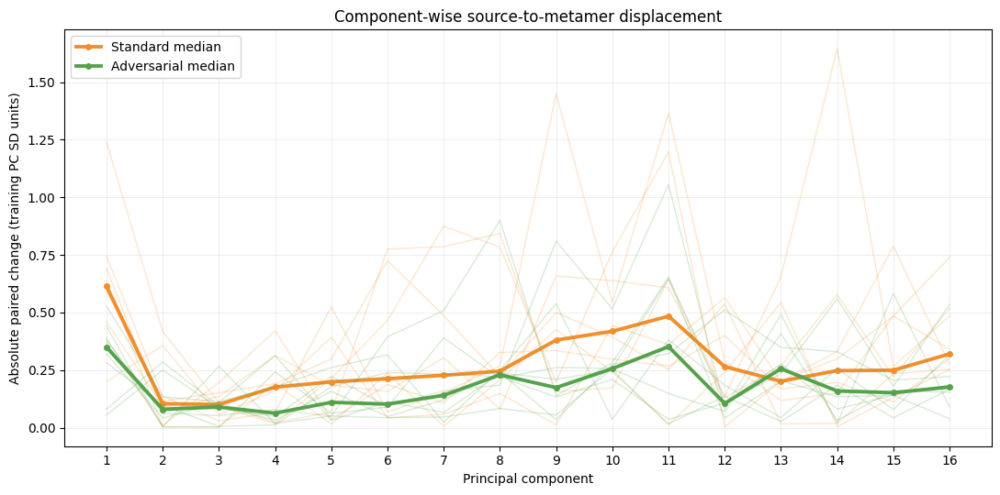

In [ ]:
fig, ax = plt.subplots(figsize=(11, 5.5))
for condition in ('standard', 'adversarial'):
    absolute_delta = np.abs(delta_z[condition])
    for i in range(len(sample_ids)):
        ax.plot(pcs, absolute_delta[i], color=COLORS[condition], alpha=0.22, linewidth=1)
    ax.plot(pcs, np.median(absolute_delta, axis=0), color=COLORS[condition], linewidth=2.8,
            marker='o', markersize=4, label=f'{condition.title()} median')
ax.set_xlabel('Principal component')
ax.set_ylabel('Absolute paired change (training PC SD units)')
ax.set_title('Component-wise source-to-metamer displacement')
ax.set_xticks(pcs)
ax.grid(alpha=0.2)
ax.legend()
fig.tight_layout()
fig.savefig(FIGURE_DIR / 'pca_viz_05_component_displacement_profiles.png', dpi=200, bbox_inches='tight')
plt.show()

## 7. Paired distance as a function of retained PCA dimensions

For each triplet, calculate Euclidean source-to-metamer distance using the first 1, 2, 4, 8 and 16 retained PCs (limited by the selected PCA dimension). This shows whether the standard/adversarial contrast is already visible in the leading PCs or accumulates across the representation.

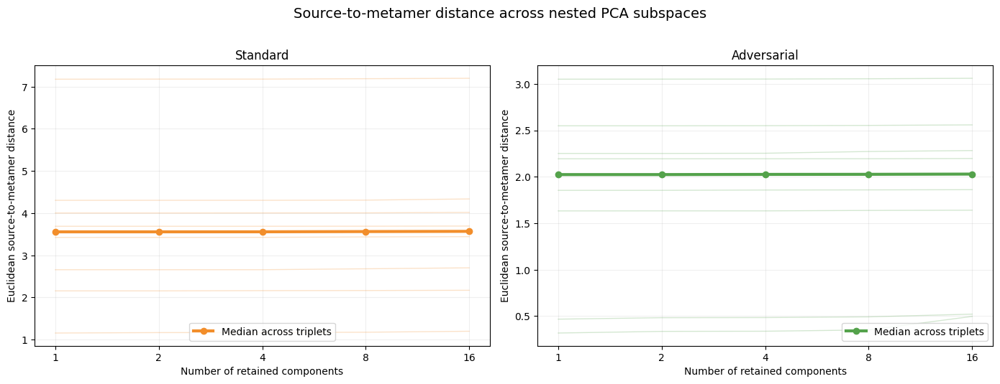

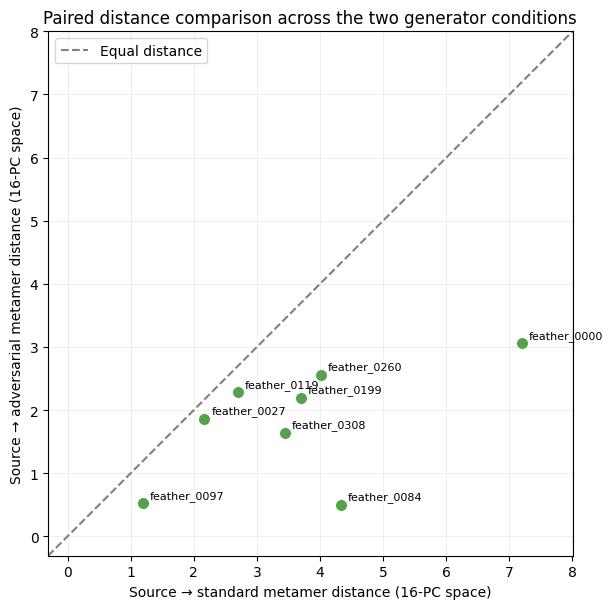

Mean 16-PC distance — standard: 3.5939
Mean 16-PC distance — adversarial: 1.8273
Triplets with adversarial distance < standard distance: 8 / 8


In [ ]:
k_values = [k for k in (1, 2, 4, 8, 16) if k <= SELECTED_K]
distance_by_k = []
for condition in ('standard', 'adversarial'):
    difference = scores[condition] - scores['source']
    for k in k_values:
        d = np.linalg.norm(difference[:, :k], axis=1)
        for i, sample_id in enumerate(sample_ids):
            distance_by_k.append({'sample_id': sample_id, 'condition': condition,
                                  'n_components': k, 'distance': float(d[i])})
distance_by_k = pd.DataFrame(distance_by_k)
distance_by_k.to_csv(RUN_DIR / 'pca_development_distance_by_component_count.csv', index=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))
for ax, condition in zip(axes, ('standard', 'adversarial')):
    subset = distance_by_k[distance_by_k['condition'].eq(condition)]
    for sample_id in sample_ids:
        one = subset[subset['sample_id'].eq(sample_id)].sort_values('n_components')
        ax.plot(one['n_components'], one['distance'], color=COLORS[condition], alpha=0.25, linewidth=1)
    summary = subset.groupby('n_components')['distance'].median().reindex(k_values)
    ax.plot(k_values, summary.values, color=COLORS[condition], marker='o', linewidth=3, label='Median across triplets')
    ax.set_xscale('log', base=2)
    ax.set_xticks(k_values)
    ax.set_xticklabels([str(k) for k in k_values])
    ax.set_xlabel('Number of retained components')
    ax.set_ylabel('Euclidean source-to-metamer distance')
    ax.set_title(f'{condition.title()}')
    ax.grid(alpha=0.2)
    ax.legend()
fig.suptitle('Source-to-metamer distance across nested PCA subspaces', y=1.02, fontsize=14)
fig.tight_layout()
fig.savefig(FIGURE_DIR / 'pca_viz_06_distance_by_component_count.png', dpi=200, bbox_inches='tight')
plt.show()

# Direct comparison at the selected dimension.
std_d = np.linalg.norm(scores['standard'] - scores['source'], axis=1)
adv_d = np.linalg.norm(scores['adversarial'] - scores['source'], axis=1)
lo = min(float(std_d.min()), float(adv_d.min()))
hi = max(float(std_d.max()), float(adv_d.max()))
pad = max((hi - lo) * 0.12, 0.1)
fig, ax = plt.subplots(figsize=(6.8, 6.2))
ax.scatter(std_d, adv_d, c=COLORS['adversarial'], s=75, edgecolor='white', linewidth=0.7)
ax.plot([lo - pad, hi + pad], [lo - pad, hi + pad], linestyle='--', color='gray', label='Equal distance')
for i, sample_id in enumerate(sample_ids):
    ax.annotate(sample_id, (std_d[i], adv_d[i]), xytext=(5, 4), textcoords='offset points', fontsize=8)
ax.set_xlim(lo - pad, hi + pad)
ax.set_ylim(lo - pad, hi + pad)
ax.set_aspect('equal', adjustable='box')
ax.set_xlabel('Source → standard metamer distance (16-PC space)')
ax.set_ylabel('Source → adversarial metamer distance (16-PC space)')
ax.set_title('Paired distance comparison across the two generator conditions')
ax.grid(alpha=0.2)
ax.legend()
fig.tight_layout()
fig.savefig(FIGURE_DIR / 'pca_viz_07_standard_vs_adversarial_distance.png', dpi=200, bbox_inches='tight')
plt.show()

print('Mean 16-PC distance — standard:', round(float(std_d.mean()), 4))
print('Mean 16-PC distance — adversarial:', round(float(adv_d.mean()), 4))
print('Triplets with adversarial distance < standard distance:', int(np.sum(adv_d < std_d)), '/', len(sample_ids))

## 8. PCA component loadings across the 384 observer channels

A PCA component is a weighted direction across the 384 pooled ConvNeXt channels. These plots show those weights (loadings). Channel indices do not have human-readable semantic labels by default; a large loading means that the channel contributes strongly to that mathematical direction, not that it is a named visual concept.

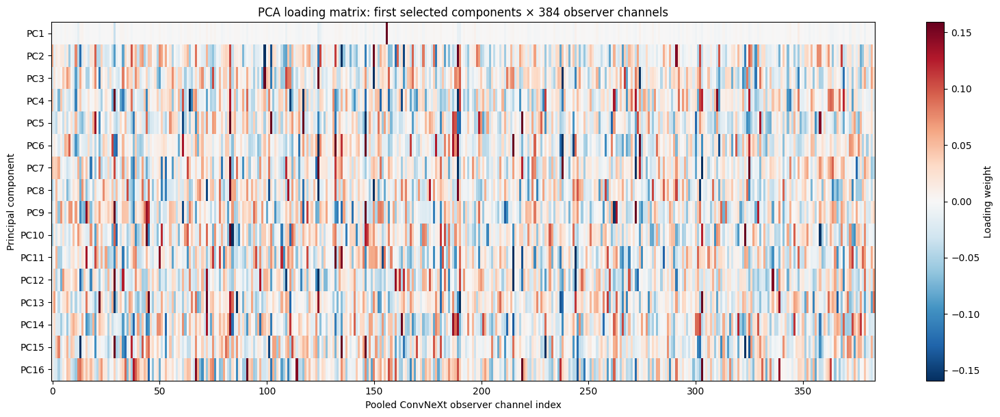

 component  rank_by_absolute_loading  observer_channel   loading  absolute_loading
         1                         1               156  0.997425          0.997425
         1                         2                29 -0.036543          0.036543
         1                         3               124 -0.020698          0.020698
         1                         4                12 -0.015116          0.015116
         1                         5               190 -0.013615          0.013615
         1                         6               189 -0.012146          0.012146
         1                         7               348  0.011774          0.011774
         1                         8               125 -0.011599          0.011599
         1                         9               146 -0.008873          0.008873
         1                        10               109 -0.008857          0.008857
         1                        11               379 -0.007947          0.007947
    

In [ ]:
loadings = pca.components_[:SELECTED_K, :]
loading_limit = max(float(np.quantile(np.abs(loadings), 0.99)), 1e-6)
fig, ax = plt.subplots(figsize=(16, 6.2))
im = ax.imshow(loadings, aspect='auto', cmap='RdBu_r', vmin=-loading_limit, vmax=loading_limit,
               interpolation='nearest')
ax.set_xlabel('Pooled ConvNeXt observer channel index')
ax.set_ylabel('Principal component')
ax.set_yticks(np.arange(SELECTED_K))
ax.set_yticklabels([f'PC{i}' for i in range(1, SELECTED_K + 1)])
ax.set_title('PCA loading matrix: first selected components × 384 observer channels')
fig.colorbar(im, ax=ax, label='Loading weight')
fig.tight_layout()
fig.savefig(FIGURE_DIR / 'pca_viz_08_loading_matrix.png', dpi=200, bbox_inches='tight')
plt.show()

TOP_N = 12
top_rows = []
for pc_index in range(SELECTED_K):
    order = np.argsort(np.abs(loadings[pc_index]))[::-1][:TOP_N]
    for rank, channel in enumerate(order, start=1):
        top_rows.append({
            'component': pc_index + 1,
            'rank_by_absolute_loading': rank,
            'observer_channel': int(channel),
            'loading': float(loadings[pc_index, channel]),
            'absolute_loading': float(abs(loadings[pc_index, channel])),
        })
top_loadings = pd.DataFrame(top_rows)
top_loadings.to_csv(RUN_DIR / 'pca_top_channel_loadings.csv', index=False)
print(top_loadings.head(36).to_string(index=False))

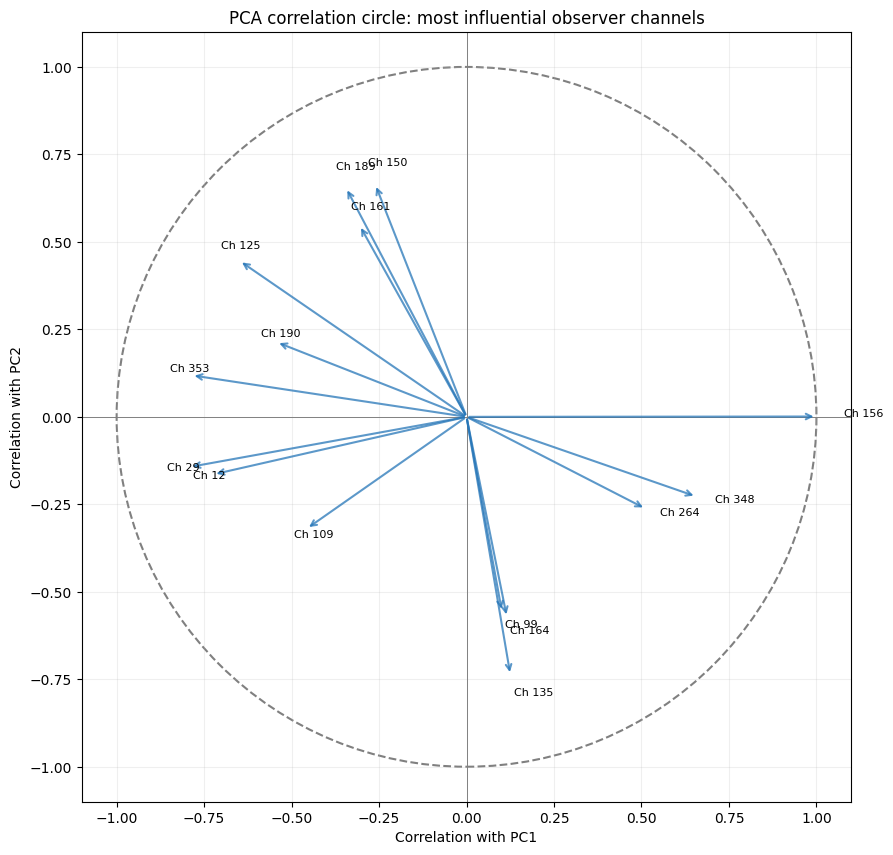

Channels with the strongest combined PC1–PC2 correlations:
[156, 29, 353, 125, 135, 12, 189, 150, 348, 161, 164, 190, 264, 99, 109]


In [ ]:
# ================================================================
# FIGURE: PCA VARIABLE CORRELATION CIRCLE
# ================================================================

channel_sd = np.std(
    X_train_check,
    axis=0,
    ddof=1
)

component_sd = np.sqrt(
    pca.explained_variance_[:2]
)

# Correlation between each observer channel and PC1 / PC2.
correlation_coordinates = (
    pca.components_[:2].T
    * component_sd[None, :]
) / np.maximum(channel_sd[:, None], 1e-10)

importance = np.linalg.norm(
    correlation_coordinates,
    axis=1
)

TOP_CHANNELS = 15

top_channel_indices = np.argsort(
    importance
)[::-1][:TOP_CHANNELS]

fig, ax = plt.subplots(figsize=(9, 9))

circle = plt.Circle(
    (0, 0),
    1,
    fill=False,
    color='gray',
    linestyle='--',
    linewidth=1.5
)

ax.add_patch(circle)

for channel in top_channel_indices:

    x = correlation_coordinates[channel, 0]
    y = correlation_coordinates[channel, 1]

    ax.annotate(
        '',
        xy=(x, y),
        xytext=(0, 0),
        arrowprops=dict(
            arrowstyle='->',
            color='#2676B8',
            linewidth=1.5,
            alpha=0.75
        )
    )

    ax.text(
        x * 1.08,
        y * 1.08,
        f'Ch {channel}',
        fontsize=8
    )

ax.axhline(0, color='gray', linewidth=0.7)
ax.axvline(0, color='gray', linewidth=0.7)

ax.set_xlim(-1.1, 1.1)
ax.set_ylim(-1.1, 1.1)

ax.set_aspect('equal')

ax.set_xlabel('Correlation with PC1')
ax.set_ylabel('Correlation with PC2')

ax.set_title(
    'PCA correlation circle: most influential observer channels'
)

ax.grid(alpha=0.2)

plt.tight_layout()

fig.savefig(
    FIGURE_DIR / 'pca_viz_13_channel_correlation_circle.png',
    dpi=220,
    bbox_inches='tight'
)

plt.show()

print("Channels with the strongest combined PC1–PC2 correlations:")
print(top_channel_indices.tolist())

## 9. Put the PCA measurements next to the actual development images

This gallery reads the already-downloaded development files from the Notebook 02 manifest. It is an interpretive aid: the thumbnails show what the images look like, while the distance column quantifies their displacement in the frozen common-observer PCA space.

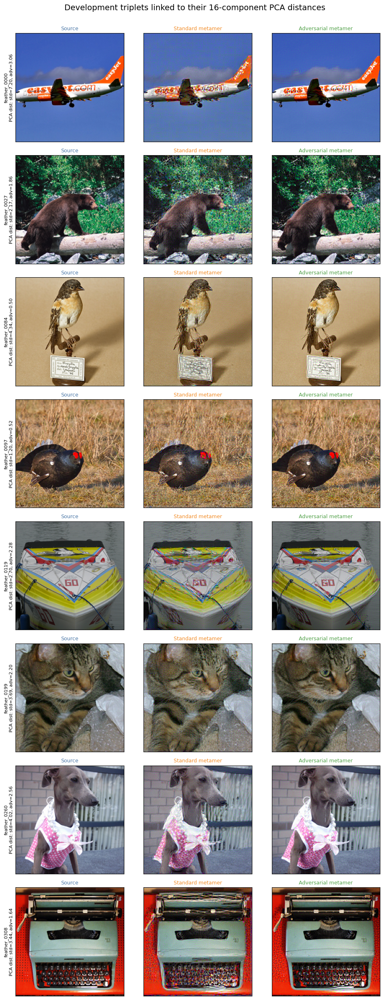

In [ ]:
manifest_path = PROJECT_ROOT / 'stimuli' / 'manifests' / 'stimulus_manifest.csv'
if not manifest_path.is_file():
    raise FileNotFoundError(f'Notebook 02 stimulus manifest not found: {manifest_path}')
manifest = pd.read_csv(manifest_path)
dev_manifest = manifest.loc[manifest['subset'].astype(str).eq('development')].copy()
if len(dev_manifest) != 8:
    raise ValueError(f'Expected eight development triplets in manifest, found {len(dev_manifest)}')

# Map each manifest row to Notebook 03's sample_id using the saved source filename.
def sample_id_from_path(path_value):
    stem = Path(str(path_value)).stem
    return '_'.join(stem.split('_')[:2])

dev_manifest['sample_id'] = dev_manifest['source_saved_path'].map(sample_id_from_path)
if set(dev_manifest['sample_id']) != set(sample_ids):
    raise ValueError(
        'Manifest development IDs do not match PCA embedding IDs. '
        f'Manifest={sorted(dev_manifest.sample_id.tolist())}; PCA={sample_ids}'
    )

distance_lookup = {
    sid: (float(std_d[i]), float(adv_d[i])) for i, sid in enumerate(sample_ids)
}
dev_manifest = dev_manifest.set_index('sample_id').loc[sample_ids].reset_index()

fig, axes = plt.subplots(len(sample_ids), 3, figsize=(10, 3.05 * len(sample_ids)), squeeze=False)
image_columns = [
    ('source_saved_path', 'Source', COLORS['source']),
    ('standard_saved_path', 'Standard metamer', COLORS['standard']),
    ('adversarial_saved_path', 'Adversarial metamer', COLORS['adversarial']),
]
for row_i, row in dev_manifest.iterrows():
    sid = row['sample_id']
    d_std, d_adv = distance_lookup[sid]
    for col_i, (path_col, label, colour) in enumerate(image_columns):
        image_path = Path(str(row[path_col]))
        if not image_path.is_file():
            raise FileNotFoundError(f'Missing development stimulus image: {image_path}')
        with Image.open(image_path) as img:
            axes[row_i, col_i].imshow(img.convert('RGB'))
        axes[row_i, col_i].set_xticks([])
        axes[row_i, col_i].set_yticks([])
        axes[row_i, col_i].set_title(label, color=colour, fontsize=9)
    axes[row_i, 0].set_ylabel(f'{sid}\nPCA dist: std={d_std:.2f}, adv={d_adv:.2f}', fontsize=8)

fig.suptitle('Development triplets linked to their 16-component PCA distances', y=1.002, fontsize=14)
fig.tight_layout()
fig.savefig(FIGURE_DIR / 'pca_viz_09_development_image_triplets_with_distances.png', dpi=180, bbox_inches='tight')
plt.show()

In [ ]:
# ================================================================
# ADVANCED: SPATIAL PCA — FIT ON IMAGENETTE TRAIN ONLY
# ================================================================

from sklearn.decomposition import IncrementalPCA

SPATIAL_N_COMPONENTS = 8
SPATIAL_BATCH_IMAGES = 64

SPATIAL_PCA_DIR = RUN_DIR / 'spatial_pca'
SPATIAL_PCA_DIR.mkdir(exist_ok=True)

SPATIAL_PCA_PATH = (
    SPATIAL_PCA_DIR / 'spatial_incremental_pca_8_components.joblib'
)

if SPATIAL_PCA_PATH.is_file():

    spatial_pca = joblib.load(SPATIAL_PCA_PATH)
    print("Loaded existing spatial PCA model.")

else:

    spatial_train_path = (
        PROJECT_ROOT
        / 'activations'
        / 'natural_images'
        / 'train'
        / 'spatial_activations.npy'
    )

    spatial_train = np.load(
        spatial_train_path,
        mmap_mode='r',
        allow_pickle=False
    )

    assert spatial_train.shape == (9469, 384, 14, 14)

    spatial_pca = IncrementalPCA(
        n_components=SPATIAL_N_COMPONENTS,
        batch_size=8192
    )

    for start in range(
        0,
        len(spatial_train),
        SPATIAL_BATCH_IMAGES
    ):

        end = min(
            start + SPATIAL_BATCH_IMAGES,
            len(spatial_train)
        )

        # B,C,H,W -> (B*H*W),C
        batch = np.asarray(
            spatial_train[start:end],
            dtype=np.float32
        )

        batch = batch.transpose(
            0, 2, 3, 1
        ).reshape(-1, 384)

        spatial_pca.partial_fit(batch)

        print(
            f"Spatial PCA fitting: {end:,}/{len(spatial_train):,} images"
        )

    joblib.dump(
        spatial_pca,
        SPATIAL_PCA_PATH,
        compress=3
    )

    print("Spatial PCA fitted and saved.")

print(
    "Spatial PCA explained variance:",
    spatial_pca.explained_variance_ratio_
)

Spatial PCA fitting: 64/9,469 images
Spatial PCA fitting: 128/9,469 images
Spatial PCA fitting: 192/9,469 images
Spatial PCA fitting: 256/9,469 images
Spatial PCA fitting: 320/9,469 images
Spatial PCA fitting: 384/9,469 images
Spatial PCA fitting: 448/9,469 images
Spatial PCA fitting: 512/9,469 images
Spatial PCA fitting: 576/9,469 images
Spatial PCA fitting: 640/9,469 images
Spatial PCA fitting: 704/9,469 images
Spatial PCA fitting: 768/9,469 images
Spatial PCA fitting: 832/9,469 images
Spatial PCA fitting: 896/9,469 images
Spatial PCA fitting: 960/9,469 images
Spatial PCA fitting: 1,024/9,469 images
Spatial PCA fitting: 1,088/9,469 images
Spatial PCA fitting: 1,152/9,469 images
Spatial PCA fitting: 1,216/9,469 images
Spatial PCA fitting: 1,280/9,469 images
Spatial PCA fitting: 1,344/9,469 images
Spatial PCA fitting: 1,408/9,469 images
Spatial PCA fitting: 1,472/9,469 images
Spatial PCA fitting: 1,536/9,469 images
Spatial PCA fitting: 1,600/9,469 images
Spatial PCA fitting: 1,664/9,46

In [ ]:
# ================================================================
# SPATIAL PCA — PROJECT SOURCE AND METAMER ACTIVATION MAPS
# ================================================================

spatial_dev_maps = {}

# We will use the first 4 components for standardization and mapping
N_MAP_COMPONENTS = 4
spatial_pc_sd = np.sqrt(
    np.maximum(
        spatial_pca.explained_variance_[:N_MAP_COMPONENTS],
        1e-10
    )
)

for condition, directory in FEATHER_ACTIVATION_DIRS.items():

    spatial_path = directory / 'spatial_activations.npy'
    metadata_path = directory / 'metadata.csv'

    spatial_array = np.load(
        spatial_path,
        mmap_mode='r',
        allow_pickle=False
    )

    metadata = pd.read_csv(metadata_path)

    metadata['sample_id'] = metadata['filename'].map(
        get_pca_sample_id
    )

    dev_meta = metadata.loc[
        metadata['split'].astype(str).eq('development')
    ].copy()

    dev_meta = dev_meta.set_index(
        'sample_id'
    ).loc[sample_ids]

    indices = (
        dev_meta['activation_index']
        .astype(int)
        .to_numpy()
    )

    X = np.asarray(
        spatial_array[indices],
        dtype=np.float32
    )

    assert X.shape == (8, 384, 14, 14)

    # (8,384,14,14) -> (8*14*14,384)
    X_positions = X.transpose(
        0, 2, 3, 1
    ).reshape(-1, 384)

    Z_positions = spatial_pca.transform(
        X_positions
    )

    Z_maps = Z_positions.reshape(
        8, 14, 14, SPATIAL_N_COMPONENTS
    )

    # Slice Z_maps to only keep the first 4 components matching spatial_pc_sd shape
    Z_maps_subset = Z_maps[..., :N_MAP_COMPONENTS]

    # Express scores in natural-image training PC standard deviations.
    Z_maps_standardized = Z_maps_subset / spatial_pc_sd[None, None, None, :]

    spatial_dev_maps[condition] = Z_maps_standardized

print("Spatial PCA projections complete.")

for condition in CONDITIONS:
    print(
        condition,
        spatial_dev_maps[condition].shape
    )

Spatial PCA projections complete.
source (8, 14, 14, 4)
standard (8, 14, 14, 4)
adversarial (8, 14, 14, 4)


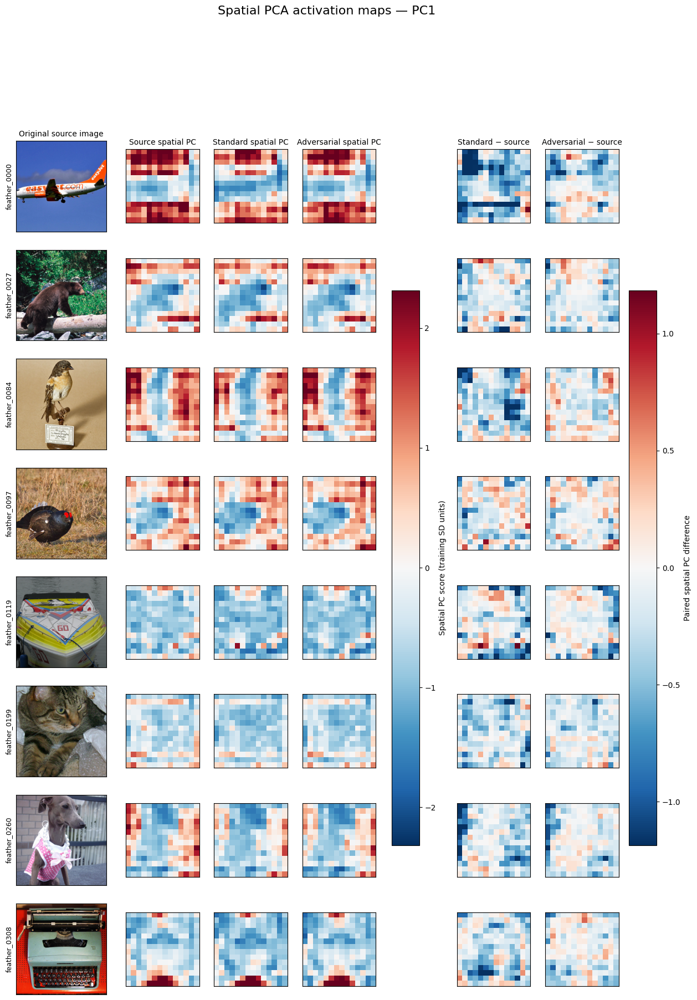

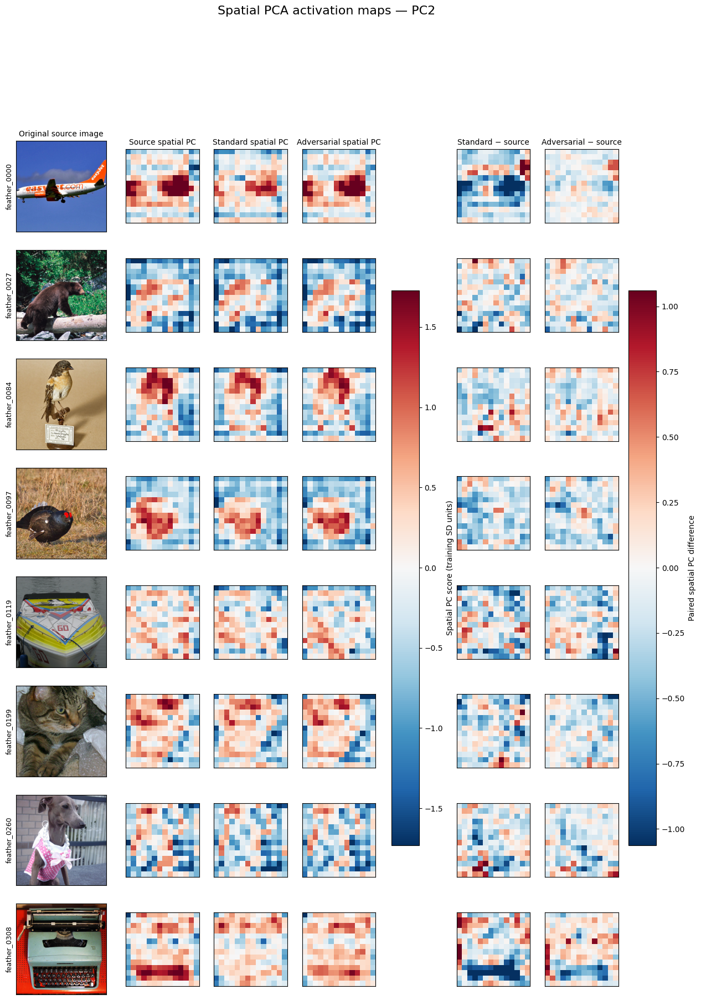

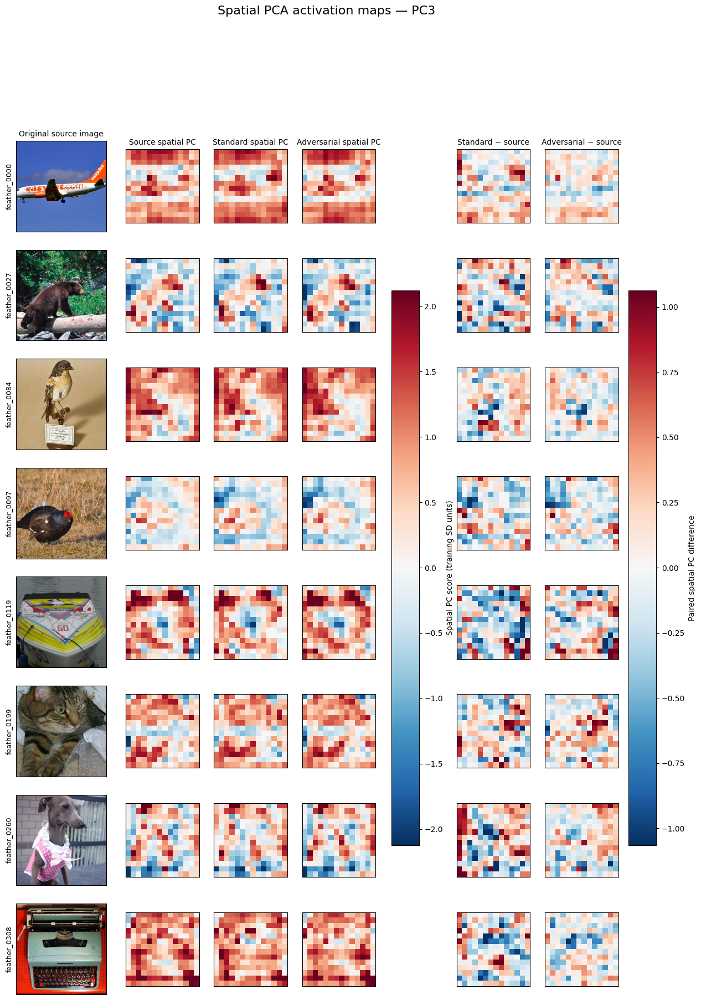

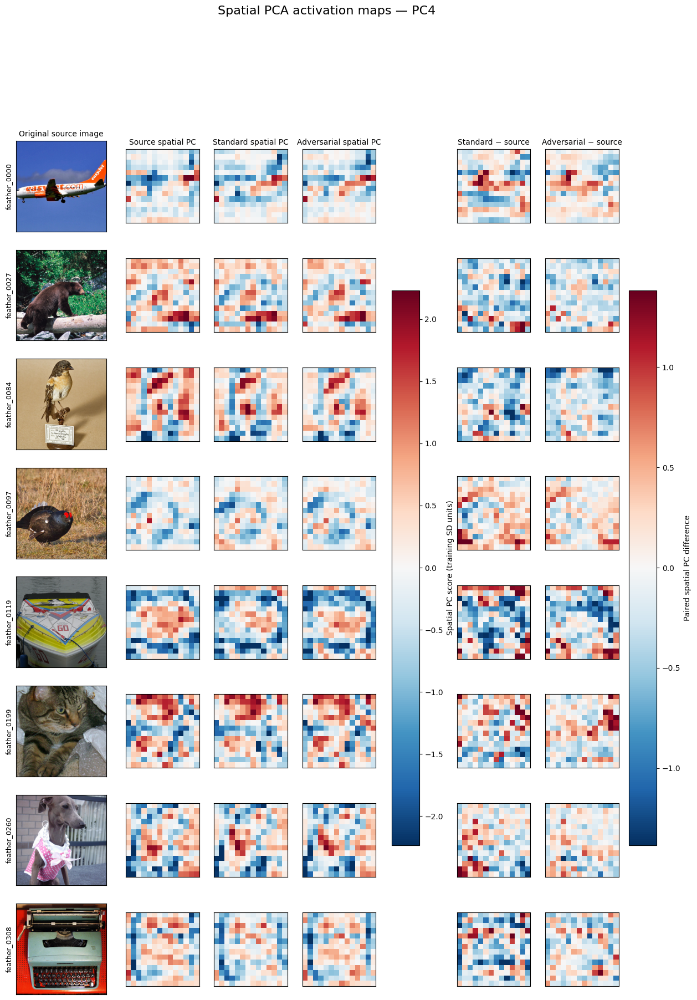

In [ ]:
# ================================================================
# FIGURE: SPATIAL PCA MAPS — PC1 TO PC4
# ================================================================

dev_image_lookup = (
    dev_manifest
    .set_index('sample_id')['source_saved_path']
    .to_dict()
)

for pc_index in range(4):

    source_maps = spatial_dev_maps['source'][:, :, :, pc_index]
    standard_maps = spatial_dev_maps['standard'][:, :, :, pc_index]
    adversarial_maps = spatial_dev_maps['adversarial'][:, :, :, pc_index]

    standard_difference = standard_maps - source_maps
    adversarial_difference = adversarial_maps - source_maps

    condition_limit = np.quantile(
        np.abs(np.concatenate([
            source_maps.ravel(),
            standard_maps.ravel(),
            adversarial_maps.ravel()
        ])),
        0.98
    )

    difference_limit = np.quantile(
        np.abs(np.concatenate([
            standard_difference.ravel(),
            adversarial_difference.ravel()
        ])),
        0.98
    )

    fig, axes = plt.subplots(
        8, 6,
        figsize=(15, 20),
        squeeze=False
    )

    column_titles = [
        'Original source image',
        'Source spatial PC',
        'Standard spatial PC',
        'Adversarial spatial PC',
        'Standard − source',
        'Adversarial − source'
    ]

    for col, title in enumerate(column_titles):
        axes[0, col].set_title(title, fontsize=10)

    for i, sid in enumerate(sample_ids):

        # Original image.
        image_path = Path(
            dev_image_lookup[sid]
        )

        with Image.open(image_path) as img:
            axes[i, 0].imshow(img.convert('RGB'))

        maps = [
            source_maps[i],
            standard_maps[i],
            adversarial_maps[i]
        ]

        differences = [
            standard_difference[i],
            adversarial_difference[i]
        ]

        for col, activation_map in enumerate(maps, start=1):

            axes[i, col].imshow(
                activation_map,
                cmap='RdBu_r',
                vmin=-condition_limit,
                vmax=condition_limit,
                interpolation='nearest'
            )

        for col, difference_map in enumerate(differences, start=4):

            axes[i, col].imshow(
                difference_map,
                cmap='RdBu_r',
                vmin=-difference_limit,
                vmax=difference_limit,
                interpolation='nearest'
            )

        axes[i, 0].set_ylabel(
            sid,
            fontsize=9
        )

        for ax in axes[i]:
            ax.set_xticks([])
            ax.set_yticks([])

    fig.colorbar(
        plt.cm.ScalarMappable(
            norm=plt.Normalize(-condition_limit, condition_limit),
            cmap='RdBu_r'
        ),
        ax=axes[:, 1:4].ravel().tolist(),
        shrink=0.65,
        label='Spatial PC score (training SD units)'
    )

    fig.colorbar(
        plt.cm.ScalarMappable(
            norm=plt.Normalize(-difference_limit, difference_limit),
            cmap='RdBu_r'
        ),
        ax=axes[:, 4:6].ravel().tolist(),
        shrink=0.65,
        label='Paired spatial PC difference'
    )

    fig.suptitle(
        f'Spatial PCA activation maps — PC{pc_index + 1}',
        fontsize=16,
        y=1.002
    )

    fig.savefig(
        SPATIAL_PCA_DIR /
        f'spatial_pca_pc{pc_index + 1}_development_maps.png',
        dpi=200,
        bbox_inches='tight'
    )

    plt.show()

## 10. Summary and saved outputs

The figures are descriptive analyses of the eight development triplets only. They should guide interpretation and identify useful metrics; they are not confirmatory evidence or a substitute for the later primary-evaluation analysis.

In [ ]:
summary = pd.DataFrame({
    'metric': [
        'development_triplets',
        'selected_components',
        'cumulative_variance_selected_components',
        'mean_source_to_standard_distance',
        'mean_source_to_adversarial_distance',
        'triplets_adversarial_closer_in_selected_PCA_space',
    ],
    'value': [
        len(sample_ids),
        SELECTED_K,
        float(explained[:SELECTED_K].sum()),
        float(std_d.mean()),
        float(adv_d.mean()),
        int(np.sum(adv_d < std_d)),
    ],
})
summary.to_csv(RUN_DIR / 'pca_visualization_extension_summary.csv', index=False)

figure_files = sorted(FIGURE_DIR.glob('pca_viz_*.png'))
print(summary.to_string(index=False))
print('\nSaved figures:')
for path in figure_files:
    print(' -', path.name)
print('\nAdditional CSVs:')
for name in [
    'pca_development_component_displacements.csv',
    'pca_development_distance_by_component_count.csv',
    'pca_top_channel_loadings.csv',
    'pca_visualization_extension_summary.csv',
]:
    print(' -', name)
print('\nAll outputs saved under:', RUN_DIR)

                                           metric     value
                             development_triplets  8.000000
                              selected_components 16.000000
          cumulative_variance_selected_components  0.960058
                 mean_source_to_standard_distance  3.593865
              mean_source_to_adversarial_distance  1.827349
triplets_adversarial_closer_in_selected_PCA_space  8.000000

Saved figures:
 - pca_viz_00_channel_variance_audit.png
 - pca_viz_01_scree_first_selected_components.png
 - pca_viz_02_paired_projection_planes.png
 - pca_viz_03_condition_score_heatmaps.png
 - pca_viz_04_paired_component_displacements.png
 - pca_viz_05_component_displacement_profiles.png
 - pca_viz_06_distance_by_component_count.png
 - pca_viz_07_standard_vs_adversarial_distance.png
 - pca_viz_08_loading_matrix.png
 - pca_viz_09_development_image_triplets_with_distances.png
 - pca_viz_10_activation_reconstruction_heatmaps.png
 - pca_viz_11_representational_similarity_mat